# Detecção de Fraudes

## Isolation Forest × Regressão Logística

**Integrantes**  
Guilherme Nunes — RM558989  
Kaique Zaffarani — RM556677  
Pedro Josué — RM554913

---

## Introdução

Fraudes são eventos raros: há muito mais transações legítimas do que fraudulentas. Isso torna o problema **desbalanceado** e exige atenção especial aos erros. Neste notebook comparamos:

- **Regressão Logística:** método supervisionado, isto é, aprende usando exemplos já rotulados.
- **Isolation Forest:** método não supervisionado, isto é, procura observações incomuns sem usar o rótulo durante o treinamento.
- **Com e sem PCA:** PCA (*Principal Component Analysis*) cria combinações dos atributos e pode reduzir a quantidade de dimensões preservando a maior parte da variação dos dados.

## Configuração do ambiente

In [ ]:
import os
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, classification_report,
    confusion_matrix, f1_score, precision_recall_curve, precision_score,
    recall_score, roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", palette="deep")

print(f"Python pronto | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")

Python pronto | pandas 2.2.3 | scikit-learn 1.6.1


In [ ]:
import urllib.request

# Credit Card Fraud Detection (ULB, publicado no Kaggle): 284.807 transações, 150 MB.
# Cópia pública do mesmo arquivo, usada no tutorial oficial do TensorFlow sobre dados desbalanceados.
URL_DATASET = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
CAMINHO_DATASET = Path("creditcard.csv")

if not CAMINHO_DATASET.exists():
    print("Baixando creditcard.csv (~150 MB)...")
    urllib.request.urlretrieve(URL_DATASET, CAMINHO_DATASET)

print(f"Dataset disponível em {CAMINHO_DATASET.resolve()} ({CAMINHO_DATASET.stat().st_size / 1e6:.0f} MB)")

# Parte 1 — Análise Exploratória

### 1.1 Carregamento e conferência

In [ ]:
df = pd.read_csv(CAMINHO_DATASET)

colunas_esperadas = {"Time", "Amount", "Class", *[f"V{i}" for i in range(1, 29)]}
faltantes = colunas_esperadas.difference(df.columns)
if faltantes:
    raise ValueError(f"O CSV não tem as colunas esperadas: {sorted(faltantes)}")

print(f"Dimensões: {df.shape[0]:,} linhas × {df.shape[1]} colunas")
display(df.head())

Dimensões: 284,807 linhas × 31 colunas


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [ ]:
resumo_base = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "ausentes": df.isna().sum(),
    "mínimo": df.min(numeric_only=True),
    "máximo": df.max(numeric_only=True),
}).fillna("—")

display(resumo_base)
print(f"Linhas duplicadas: {df.duplicated().sum():,}")
print(f"Valores ausentes: {df.isna().sum().sum():,}")

,tipo,ausentes,mínimo,máximo
Time,float64,0,0.000000,172792.000000
V1,float64,0,-56.407510,2.454930
V2,float64,0,-72.715728,22.057729
V3,float64,0,-48.325589,9.382558
V4,float64,0,-5.683171,16.875344
V5,float64,0,-113.743307,34.801666
V6,float64,0,-26.160506,73.301626
V7,float64,0,-43.557242,120.589494
V8,float64,0,-73.216718,20.007208
V9,float64,0,-13.434066,15.594995


Linhas duplicadas: 1,081
Valores ausentes: 0


### Decisão sobre as linhas duplicadas

Foram identificadas 1.081 linhas duplicadas. Elas serão mantidas para preservar a composição original do arquivo fornecido e permitir comparação com o benchmark completo. Como não existe um identificador único de transação, não é possível afirmar que todas representam erros de coleta; algumas podem corresponder a transações distintas com os mesmos atributos anonimizados.

Essa decisão é uma limitação do experimento: duplicatas idênticas podem aparecer em divisões diferentes e tornar a avaliação ligeiramente otimista. Em um projeto de produção, investigaríamos identificadores e horários completos antes de decidir pela remoção.

### 1.1.1 O que representam `V1` a `V28`?

As colunas `V1` a `V28` já são componentes produzidos por um **PCA aplicado pelos autores do conjunto de dados original**. Os atributos financeiros originais não foram divulgados por motivos de confidencialidade; no lugar deles, foram fornecidas combinações matemáticas anonimizadas.

Isso significa que o notebook **não criou `V1` a `V28`**. Elas já chegam prontas no arquivo `creditcard.csv`. Além delas, temos:

- `Time`: tempo transcorrido desde a primeira transação registrada;
- `Amount`: valor da transação;
- `Class`: rótulo real, em que `0` indica transação legítima e `1` indica fraude.

#### Por que aplicar PCA novamente mais adiante?

A atividade exige repetir a análise com e sem PCA. Por isso, trataremos o segundo PCA como um **experimento adicional de redução de dimensionalidade**. Ele será aplicado ao conjunto completo de 30 atributos preditores (`Time`, `V1`–`V28` e `Amount`) depois da padronização.

Essa segunda aplicação é parcialmente redundante, pois 28 atributos já vieram de um PCA. O resultado será medido, e não presumido.

### 1.2 Distribuição da variável-alvo e desbalanceamento

,quantidade,percentual (%)
Legítima (0),284315,99.8273
Fraude (1),492,0.1727


Taxa de fraude: 0.001727 (0.1727%)
Há aproximadamente 577.9 transações legítimas para cada fraude.


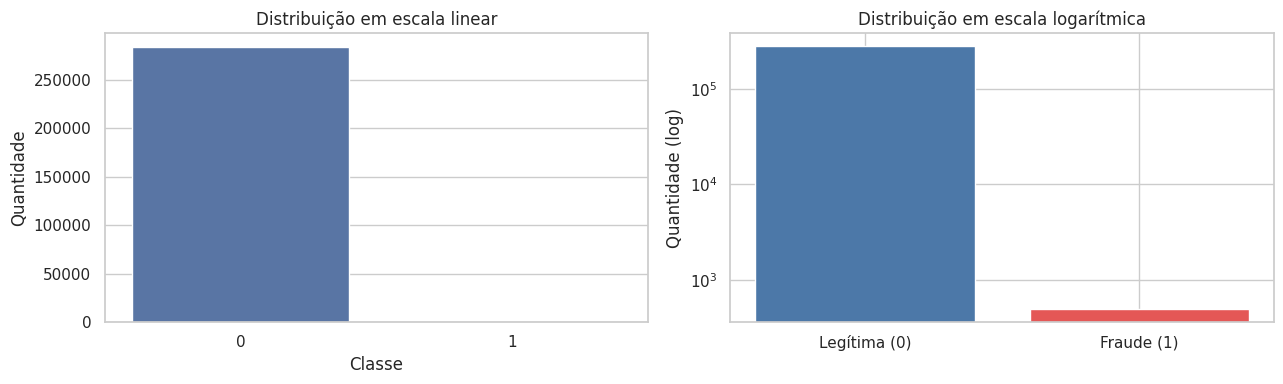

In [ ]:
contagem = df["Class"].value_counts().sort_index()
percentual = df["Class"].value_counts(normalize=True).sort_index().mul(100)
distribuicao = pd.DataFrame({"quantidade": contagem, "percentual (%)": percentual})
distribuicao.index = ["Legítima (0)", "Fraude (1)"]
display(distribuicao.round({"percentual (%)": 4}))

taxa_fraude = df["Class"].mean()
razao = contagem.loc[0] / contagem.loc[1]
print(f"Taxa de fraude: {taxa_fraude:.6f} ({taxa_fraude*100:.4f}%)")
print(f"Há aproximadamente {razao:.1f} transações legítimas para cada fraude.")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.countplot(data=df, x="Class", ax=axes[0])
axes[0].set(title="Distribuição em escala linear", xlabel="Classe", ylabel="Quantidade")
axes[0].ticklabel_format(style="plain", axis="y")

axes[1].bar(["Legítima (0)", "Fraude (1)"], contagem.values, color=["#4C78A8", "#E45756"])
axes[1].set_yscale("log")
axes[1].set(title="Distribuição em escala logarítmica", ylabel="Quantidade (log)")
plt.tight_layout()
plt.show()

### 1.3 Escala e natureza das variáveis

**Propósito desta etapa:** entender como os atributos estão representados e verificar se possuem escalas muito diferentes antes do treinamento.

Isso é importante porque `Time` e `Amount` possuem unidades e amplitudes diferentes das colunas `V1` a `V28`. Tanto a regularização da Regressão Logística quanto o PCA são influenciados pela escala numérica.

O desvio-padrão é uma medida estatística que indica o quanto os valores de um conjunto de dados se afastam da média. Mais adiante usaremos `StandardScaler`, que centraliza cada atributo em torno de zero e ajusta seu desvio-padrão para aproximadamente um.

Os gráficos abaixo também mostram se `Amount` é assimétrico e se seu comportamento visual muda entre as classes. No boxplot, `showfliers=False` apenas oculta pontos extremos no desenho para facilitar a leitura; nenhuma transação é excluída.

,count,mean,std,min,25%,50%,75%,max
Time,284807.0,9.481386e+04,47488.145955,0.000000,54201.500000,84692.000000,139320.500000,172792.000000
Amount,284807.0,8.834962e+01,250.120109,0.000000,5.600000,22.000000,77.165000,25691.160000
V1,284807.0,1.168375e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.416908e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.074095e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,9.604066e-16,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666


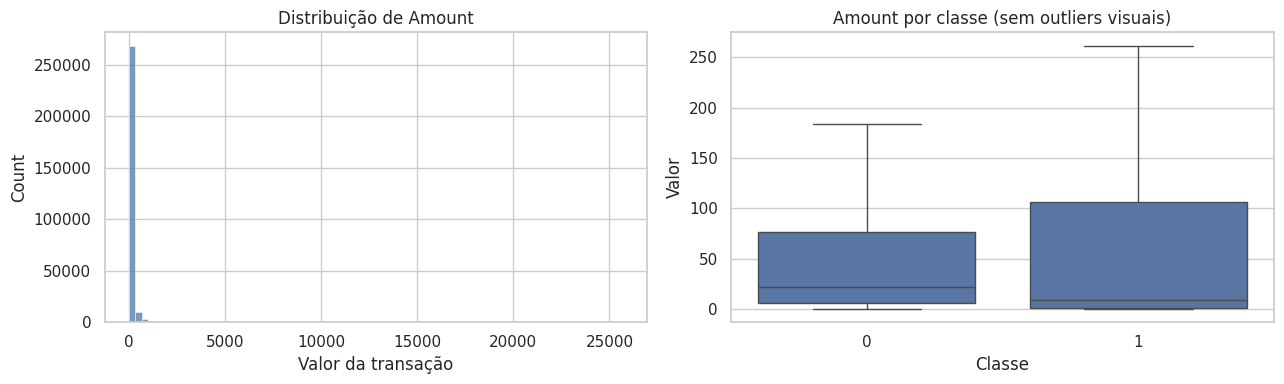

In [ ]:
display(df[["Time", "Amount", *[f"V{i}" for i in range(1, 6)]]].describe().T)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df["Amount"], bins=80, ax=axes[0], color="#4C78A8")
axes[0].set(title="Distribuição de Amount", xlabel="Valor da transação")
sns.boxplot(data=df, x="Class", y="Amount", showfliers=False, ax=axes[1])
axes[1].set(title="Amount por classe (sem outliers visuais)", xlabel="Classe", ylabel="Valor")
plt.tight_layout()
plt.show()

### 1.4 Por que o problema é desafiador?

- Fraudes são extremamente raras. Um modelo que sempre respondesse “legítima” teria acurácia próxima de 100%, mas encontraria **zero fraude**.
- Os padrões fraudulentos mudam com o tempo e podem se parecer com compras legítimas.
- Os dois tipos de erro têm custos diferentes: um falso positivo causa bloqueio indevido e trabalho de revisão; um falso negativo deixa uma fraude passar.

#### Por que a acurácia pode enganar?

A acurácia divide o total de acertos pelo total de transações. Como quase todas as transações são legítimas, acertar essa classe domina o cálculo. Assim, é possível obter mais de 99% de acurácia e ainda deixar passar uma parcela relevante das fraudes.

Por esse motivo, a acurácia será mostrada apenas como referência. A análise dará prioridade a:

- **precision:** entre os alertas emitidos, quantos eram realmente fraude;
- **recall:** entre todas as fraudes reais, quantas foram detectadas;
- **F1:** equilíbrio entre precision e recall;
- **PR-AUC:** qualidade do ranqueamento da classe rara em diferentes limiares;
- **FP e FN:** quantidades concretas de falsos positivos e falsos negativos.

> Precision, recall, F1, PR-AUC e acurácia são métricas de avaliação, não métodos de treinamento. Elas medem as previsões geradas pelo modelo. Neste trabalho, o F1 da validação orienta a escolha da configuração, enquanto o teste mede o resultado final.

## Preparação comum — treino, validação e teste

**Propósito desta etapa:** separar os dados para que a escolha dos modelos não contamine a avaliação final.

- **Treino (60%):** usado para o modelo aprender seus parâmetros.
- **Validação (20%):** usado para comparar hiperparâmetros, como `C`, regularização e `class_weight`.
- **Teste (20%):** mantido separado até o fim para estimar o desempenho em dados não usados na escolha do modelo.

### O que significa divisão estratificada?

Como a fraude representa aproximadamente 0,17% da base, uma divisão puramente aleatória poderia concentrar mais fraudes em uma parte e menos em outra. O argumento `stratify=y` preserva aproximadamente a mesma proporção de transações legítimas e fraudulentas em treino, validação e teste.

Estratificar **não cria novas fraudes e não balanceia a base**. Apenas distribui proporcionalmente os exemplos já existentes.

In [ ]:
X = df.drop(columns="Class")
y = df["Class"].astype(int)

X_treino, X_temp, y_treino, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=SEED
)
X_valid, X_teste, y_valid, y_teste = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=SEED
)

divisoes = pd.DataFrame({
    "amostras": [len(y_treino), len(y_valid), len(y_teste)],
    "fraudes": [y_treino.sum(), y_valid.sum(), y_teste.sum()],
    "taxa de fraude (%)": [100*y_treino.mean(), 100*y_valid.mean(), 100*y_teste.mean()],
}, index=["Treino", "Validação", "Teste"])
display(divisoes.round({"taxa de fraude (%)": 4}))

,amostras,fraudes,taxa de fraude (%)
Treino,170884,295,0.1726
Validação,56961,98,0.1720
Teste,56962,99,0.1738


### Pré-processamento, PCA e funções de avaliação

**Propósito desta etapa:** criar duas versões comparáveis dos mesmos dados e padronizar a forma de avaliar todos os modelos.

1. **Sem PCA:** ajustamos apenas o `StandardScaler` e mantemos os 30 atributos.
2. **Com PCA:** Com PCA: ajustamos o `StandardScaler` e, em seguida, ajustamos o PCA exclusivamente no conjunto de treino, mantendo o menor número de componentes necessários para explicar pelo menos 95% da variância dos dados de treino.

O PCA não acontece aleatoriamente em algumas transações. Ele aprende novas direções a partir das **colunas do conjunto de treino** e projeta todas as transações nessas mesmas direções. Com `svd_solver="full"`, a transformação utilizada aqui é determinística.

O ajuste é feito exclusivamente no treino com `fit_transform`. Validação e teste recebem somente `transform`. Isso evita **vazamento de dados**: informações dos conjuntos usados para avaliação não participam do cálculo da escala nem dos componentes.

Na matriz de confusão, as linhas são os rótulos reais e as colunas são as previsões. O formato é `[[VN, FP], [FN, VP]]`: verdadeiro negativo, falso positivo, falso negativo e verdadeiro positivo.

In [ ]:
def calcular_metricas(y_real, y_pred, scores=None):
    vn, fp, fn, vp = confusion_matrix(y_real, y_pred, labels=[0, 1]).ravel()
    resultado = {
        "accuracy": accuracy_score(y_real, y_pred),
        "precision": precision_score(y_real, y_pred, zero_division=0),
        "recall": recall_score(y_real, y_pred, zero_division=0),
        "f1": f1_score(y_real, y_pred, zero_division=0),
        "VN": vn, "FP": fp, "FN": fn, "VP": vp,
    }
    if scores is not None:
        resultado["pr_auc"] = average_precision_score(y_real, scores)
        resultado["roc_auc"] = roc_auc_score(y_real, scores)
    return resultado


def exibir_avaliacao(nome, y_real, y_pred, scores=None):
    metricas = calcular_metricas(y_real, y_pred, scores)
    display(Markdown(f"### {nome}"))
    cols = ["accuracy", "precision", "recall", "f1"]
    if scores is not None:
        cols += ["pr_auc", "roc_auc"]
    display(pd.DataFrame([metricas])[cols].round(4))

    cm = confusion_matrix(y_real, y_pred, labels=[0, 1])
    plt.figure(figsize=(5.2, 4))
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False,
                xticklabels=["Legítima", "Fraude"], yticklabels=["Legítima", "Fraude"])
    plt.xlabel("Previsão")
    plt.ylabel("Real")
    plt.title(f"Matriz de confusão — {nome}")
    plt.tight_layout()
    plt.show()

    fp, fn = metricas["FP"], metricas["FN"]
    print(f"Falsos positivos: {fp:,} transações legítimas geraram alerta.")
    print(f"Falsos negativos: {fn:,} fraudes não foram detectadas.")
    print(classification_report(y_real, y_pred, target_names=["Legítima", "Fraude"], digits=4, zero_division=0))
    return metricas


def preparar_dados(pca_ativo):
    etapas = [("escala", StandardScaler())]
    if pca_ativo:
        etapas.append(("pca", PCA(n_components=0.95, svd_solver="full")))
    transformador = Pipeline(etapas)
    Xt = transformador.fit_transform(X_treino)
    Xv = transformador.transform(X_valid)
    Xts = transformador.transform(X_teste)
    return transformador, Xt, Xv, Xts


dados_preparados = {}
for usa_pca in [False, True]:
    dados_preparados[usa_pca] = preparar_dados(usa_pca)
    n_atributos = dados_preparados[usa_pca][1].shape[1]
    print(f"{'Com PCA' if usa_pca else 'Sem PCA'}: {n_atributos} atributos após o pré-processamento")

Sem PCA: 30 atributos após o pré-processamento
Com PCA: 27 atributos após o pré-processamento


# Parte 2 — Regressão Logística (Supervisionado)

## 2.1 Treinamento e comparação de configurações

**Propósito desta etapa:** descobrir qual combinação de regularização, força de regularização e tratamento do desbalanceamento apresenta o melhor equilíbrio na validação.

Testaremos:

- regularizações **L1**, **L2** e **ElasticNet**;
- `C` igual a `0.01`, `0.1`, `1` e `10`;
- `class_weight` padrão ou `balanced`;
- dados com e sem o segundo PCA.

**Como interpretar os parâmetros:**

- **L1:** pode zerar coeficientes e realizar uma seleção implícita de atributos;
- **L2:** reduz os coeficientes de forma suave;
- **ElasticNet:** combina L1 e L2;
- **C:** é o inverso da força de regularização; quanto menor o `C`, mais forte a regularização;
- **`class_weight='balanced'`:** aumenta, durante o treinamento, o custo de errar a classe rara.

Ao todo são treinados 48 modelos, pois todas as combinações entre os parâmetros são avaliadas: 3 tipos de regularização (**L1**, **L2** e **ElasticNet**) × 4 valores de `C` (`0.01`, `0.1`, `1` e `10`) × 2 opções de `class_weight` (padrão e `balanced`) × 2 cenários de dados (sem PCA e com PCA).

Assim, são 24 configurações sem PCA e 24 configurações com PCA, totalizando 48 modelos. A tabela mostra os oito melhores de cada cenário, ordenados pelo F1 na validação. Portanto, ela ainda não representa o teste final.

In [ ]:
configs_lr = []
for penalidade in ["l1", "l2", "elasticnet"]:
    for C in [0.01, 0.1, 1, 10]:
        for peso in [None, "balanced"]:
            configs_lr.append({"penalty": penalidade, "C": C, "class_weight": peso})

resultados_lr_valid = []
inicio = time.time()

for usa_pca in [False, True]:
    _, Xt, Xv, _ = dados_preparados[usa_pca]
    for cfg in configs_lr:
        parametros = dict(
            penalty=cfg["penalty"], C=cfg["C"], class_weight=cfg["class_weight"],
            solver="saga" if cfg["penalty"] == "elasticnet" else "liblinear",
            max_iter=2000 if cfg["penalty"] == "elasticnet" else 500,
            tol=1e-3, random_state=SEED
        )
        if cfg["penalty"] == "elasticnet":
            parametros["l1_ratio"] = 0.5
        modelo = LogisticRegression(**parametros)
        modelo.fit(Xt, y_treino)
        pred = modelo.predict(Xv)
        score = modelo.predict_proba(Xv)[:, 1]
        linha = calcular_metricas(y_valid, pred, score)
        linha.update({"PCA": usa_pca, **cfg})
        resultados_lr_valid.append(linha)

resultados_lr_valid = pd.DataFrame(resultados_lr_valid)
print(f"Busca concluída em {(time.time()-inicio)/60:.2f} minuto(s).")

colunas_lr = ["PCA", "penalty", "C", "class_weight", "precision", "recall", "f1", "pr_auc", "FP", "FN"]
display(resultados_lr_valid.sort_values(["PCA", "f1"], ascending=[True, False])
        .groupby("PCA", as_index=False).head(8)[colunas_lr].round(4))

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Busca concluída em 38.73 minuto(s).


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,PCA,penalty,C,class_weight,precision,recall,f1,pr_auc,FP,FN
6,False,l1,10.0,None,0.8312,0.6531,0.7314,0.6761,13,34
12,False,l2,1.0,None,0.8312,0.6531,0.7314,0.6757,13,34
14,False,l2,10.0,None,0.8312,0.6531,0.7314,0.6760,13,34
4,False,l1,1.0,None,0.8205,0.6531,0.7273,0.6762,14,34
20,False,elasticnet,1.0,None,0.8378,0.6327,0.7209,0.6744,12,36
22,False,elasticnet,10.0,None,0.8378,0.6327,0.7209,0.6745,12,36
10,False,l2,0.1,None,0.8472,0.6224,0.7176,0.6763,11,37
18,False,elasticnet,0.1,None,0.8451,0.6122,0.7101,0.6714,11,38
30,True,l1,10.0,None,0.8182,0.6429,0.7200,0.6742,14,35
38,True,l2,10.0,None,0.8182,0.6429,0.7200,0.6743,14,35


## 2.2 Melhor configuração com e sem PCA — teste final

**Propósito desta etapa:** avaliar de maneira justa as duas configurações escolhidas.

Primeiro selecionamos, separadamente, o melhor modelo sem PCA e o melhor modelo com PCA usando o F1 da validação. Depois reunimos treino e validação, reajustamos somente essas configurações e avaliamos uma única vez no teste.

A acurácia aparece na tabela, mas não será usada isoladamente. Em uma base com dezenas de milhares de transações legítimas e poucas dezenas de fraudes, os verdadeiros negativos dominam seu cálculo. Por isso, a matriz de confusão, o recall da fraude, a precision, o F1, a PR-AUC, os FP e os FN são indispensáveis.

### Regressão Logística — sem PCA

,accuracy,precision,recall,f1,pr_auc,roc_auc
0,0.9992,0.8667,0.6566,0.7471,0.7718,0.9669


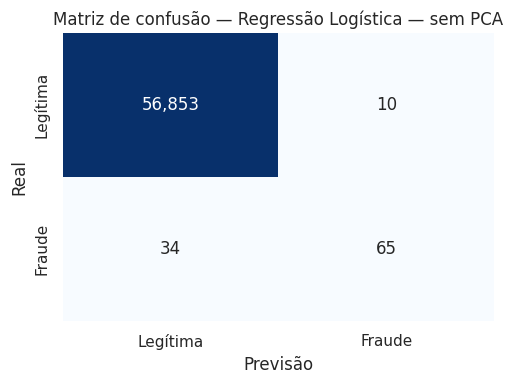

Falsos positivos: 10 transações legítimas geraram alerta.
Falsos negativos: 34 fraudes não foram detectadas.
              precision    recall  f1-score   support

    Legítima     0.9994    0.9998    0.9996     56863
      Fraude     0.8667    0.6566    0.7471        99

    accuracy                         0.9992     56962
   macro avg     0.9330    0.8282    0.8734     56962
weighted avg     0.9992    0.9992    0.9992     56962

Configuração escolhida: {'penalty': 'l1', 'C': np.float64(10.0), 'class_weight': None}


### Regressão Logística — com PCA

,accuracy,precision,recall,f1,pr_auc,roc_auc
0,0.9991,0.8571,0.6061,0.7101,0.7456,0.967


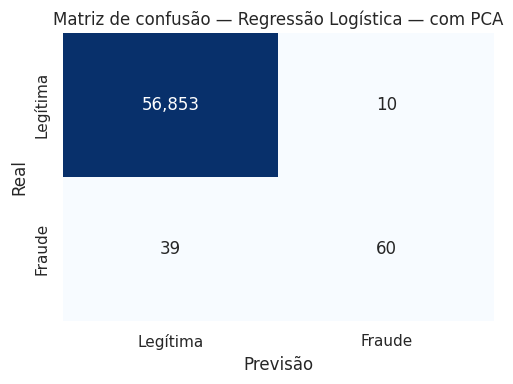

Falsos positivos: 10 transações legítimas geraram alerta.
Falsos negativos: 39 fraudes não foram detectadas.
              precision    recall  f1-score   support

    Legítima     0.9993    0.9998    0.9996     56863
      Fraude     0.8571    0.6061    0.7101        99

    accuracy                         0.9991     56962
   macro avg     0.9282    0.8029    0.8548     56962
weighted avg     0.9991    0.9991    0.9991     56962

Configuração escolhida: {'penalty': 'l2', 'C': np.float64(10.0), 'class_weight': None}


In [ ]:
X_treino_final = pd.concat([X_treino, X_valid])
y_treino_final = pd.concat([y_treino, y_valid])
avaliacoes_lr = {}
modelos_lr = {}

for usa_pca in [False, True]:
    melhor = (resultados_lr_valid[resultados_lr_valid["PCA"] == usa_pca]
              .sort_values(["f1", "pr_auc", "recall"], ascending=False).iloc[0])

    etapas = [("escala", StandardScaler())]
    if usa_pca:
        etapas.append(("pca", PCA(n_components=0.95, svd_solver="full")))
    pre = Pipeline(etapas)
    Xt_final = pre.fit_transform(X_treino_final)
    Xts = pre.transform(X_teste)

    parametros = dict(
        penalty=melhor["penalty"], C=float(melhor["C"]),
        class_weight=melhor["class_weight"],
        solver="saga" if melhor["penalty"] == "elasticnet" else "liblinear",
        max_iter=2000 if melhor["penalty"] == "elasticnet" else 500,
        tol=1e-3, random_state=SEED
    )
    if melhor["penalty"] == "elasticnet":
        parametros["l1_ratio"] = 0.5
    modelo = LogisticRegression(**parametros).fit(Xt_final, y_treino_final)
    pred = modelo.predict(Xts)
    score = modelo.predict_proba(Xts)[:, 1]
    nome = f"Regressão Logística — {'com PCA' if usa_pca else 'sem PCA'}"
    avaliacoes_lr[usa_pca] = exibir_avaliacao(nome, y_teste, pred, score)
    modelos_lr[usa_pca] = {"preprocessador": pre, "modelo": modelo, "pred": pred, "score": score, "config": melhor}
    print("Configuração escolhida:", {"penalty": melhor["penalty"], "C": melhor["C"], "class_weight": melhor["class_weight"]})

### 2.2.1 Leitura correta da acurácia

A célula abaixo transforma a matriz de confusão em uma explicação automática. Ela mostra tanto a acurácia total quanto a proporção de fraudes que passaram sem detecção. Se a acurácia permanecer alta ao mesmo tempo que muitos FN aparecem, não há contradição: isso é consequência direta do desbalanceamento.

O `macro avg` do relatório dá o mesmo peso às duas classes e é mais informativo que o `weighted avg`, porém ainda mistura o desempenho excelente da classe legítima com o desempenho da fraude. Para esta atividade, devemos observar principalmente a linha **Fraude**, a PR-AUC e os valores absolutos de FP e FN.

In [ ]:
for usa_pca in [False, True]:
    m = avaliacoes_lr[usa_pca]
    cenario = "com PCA" if usa_pca else "sem PCA"
    total_fraudes = m["VP"] + m["FN"]
    percentual_nao_detectado = 100 * m["FN"] / total_fraudes
    print(
        f"{cenario}: acurácia={m['accuracy']*100:.2f}%, "
        f"mas {m['FN']} de {total_fraudes} fraudes não foram detectadas "
        f"({percentual_nao_detectado:.2f}% das fraudes)."
    )

sem PCA: acurácia=99.92%, mas 34 de 99 fraudes não foram detectadas (34.34% das fraudes).
com PCA: acurácia=99.91%, mas 39 de 99 fraudes não foram detectadas (39.39% das fraudes).


## 2.3 Discussão dos resultados da Regressão Logística

A tabela seguinte resume, na validação, o comportamento médio dos quatro valores de `C` para cada combinação de regularização, peso de classe e uso de PCA. Ela serve para analisar tendências; a avaliação final continua sendo a apresentada no teste da seção 2.2.

In [ ]:
impacto_lr = (resultados_lr_valid
    .groupby(["PCA", "penalty", "class_weight"], dropna=False)
    [["precision", "recall", "f1", "FP", "FN"]].mean().reset_index())
impacto_lr["class_weight"] = impacto_lr["class_weight"].fillna("padrão")
display(impacto_lr.round(4))

for usa_pca in [False, True]:
    m = avaliacoes_lr[usa_pca]
    cenario = "com PCA" if usa_pca else "sem PCA"
    print(f"{cenario}: recall={m['recall']:.3f}, precision={m['precision']:.3f}, FP={m['FP']:,}, FN={m['FN']:,}.")

print("\nLeitura: pesos balanceados normalmente elevam o recall, pois erros em fraudes recebem mais peso,"
      " mas podem aumentar falsos positivos e reduzir precision. A regularização controla a complexidade;"
      " seu efeito concreto deve ser lido na tabela, pois depende dos dados.")

,PCA,penalty,class_weight,precision,recall,f1,FP,FN
0,False,elasticnet,balanced,0.0644,0.8750,0.1200,1245.25,12.25
1,False,elasticnet,padrão,0.8340,0.6046,0.7006,11.75,38.75
2,False,l1,balanced,0.0655,0.8750,0.1218,1224.00,12.25
3,False,l1,padrão,0.8228,0.6173,0.7046,13.00,37.50
4,False,l2,balanced,0.0656,0.8776,0.1221,1225.25,12.00
5,False,l2,padrão,0.8319,0.6199,0.7098,12.25,37.25
6,True,elasticnet,balanced,0.0599,0.8776,0.1122,1349.75,12.00
7,True,elasticnet,padrão,0.8273,0.5995,0.6947,12.25,39.25
8,True,l1,balanced,0.0629,0.8776,0.1174,1281.25,12.00
9,True,l1,padrão,0.8177,0.6071,0.6960,13.25,38.50


sem PCA: recall=0.657, precision=0.867, FP=10, FN=34.
com PCA: recall=0.606, precision=0.857, FP=10, FN=39.

Leitura: pesos balanceados normalmente elevam o recall, pois erros em fraudes recebem mais peso, mas podem aumentar falsos positivos e reduzir precision. A regularização controla a complexidade; seu efeito concreto deve ser lido na tabela, pois depende dos dados.


### 2.3.1 Impacto da regularização

Na validação sem PCA, L1 com `C=10` e L2 com `C=1` ou `C=10` alcançaram o mesmo F1 de 0,7314. Com PCA, os melhores resultados também ficaram próximos: L1 com `C=10` e L2 com `C=10` obtiveram F1 de 0,7200. Isso indica que, entre as melhores configurações, o tipo de regularização teve influência menor que o tratamento do desbalanceamento.

O melhor modelo final sem PCA utilizou L1 com `C=10`. Como `C` maior representa regularização mais fraca, o resultado sugere que uma penalização muito intensa não trouxe benefício adicional para a separação das fraudes. O melhor modelo com PCA utilizou L2 com `C=10`.

### 2.3.2 Efeito de tratar o desbalanceamento

`class_weight='balanced'` atua **durante o treinamento**, dando mais importância às fraudes na função de erro. Não existe uma etapa de “balancear depois do treinamento”.

Nos resultados da validação, o balanceamento elevou o recall médio para aproximadamente 0,88 e reduziu os falsos negativos para cerca de 12. Entretanto, também gerou aproximadamente 1.224 a 1.318 falsos positivos e reduziu a precision para valores próximos de 0,06. Já os modelos com peso padrão apresentaram cerca de 12 a 13 falsos positivos e precision superior a 0,81.

Portanto, o balanceamento encontrou mais fraudes, mas o custo operacional em alertas incorretos foi muito alto. Como o F1 penaliza esse desequilíbrio, os modelos finais selecionados utilizaram `class_weight=None`.

### 2.3.3 Trade-off entre precision e recall

- Priorizar **recall** significa capturar mais fraudes, aceitando mais alertas incorretos.
- Priorizar **precision** significa emitir alertas mais confiáveis, correndo o risco de deixar mais fraudes passar.
- O **F1** procura um equilíbrio matemático, mas a decisão real deveria considerar o custo financeiro de cada fraude e a capacidade da equipe de revisar alertas.

O resultado balanceado ilustra esse conflito: o recall aumentou, mas apenas cerca de 6% dos alertas correspondiam realmente a fraude. No modelo final sem PCA, a precision de 0,8667 indica alertas mais confiáveis, enquanto o recall de 0,6566 mostra que ainda há espaço para reduzir fraudes não detectadas.

### 2.3.4 Análise de falsos positivos e falsos negativos

- **Falso positivo (FP):** uma compra legítima é marcada como fraude. Pode causar bloqueio indevido, atrito com o cliente e custo de revisão.
- **Falso negativo (FN):** uma fraude é classificada como legítima. Pode causar perda financeira e risco de segurança.

No teste, os dois modelos produziram 10 falsos positivos. Entretanto, o modelo sem PCA deixou passar 34 fraudes, enquanto o modelo com PCA deixou passar 39. Assim, o segundo PCA não reduziu o custo operacional dos alertas e ainda acrescentou cinco fraudes não detectadas.

Embora as acurácias tenham permanecido próximas de 99,9%, o modelo sem PCA não detectou 34,34% das fraudes e o modelo com PCA não detectou 39,39%. Isso confirma por que a acurácia isolada seria enganosa neste problema.

# Parte 3 — Isolation Forest (Não Supervisionado)

## 3.1 Treinamento e comparação de configurações

**Propósito desta etapa:** verificar se um detector de anomalias consegue encontrar fraudes sem receber os rótulos durante o treinamento.

Isolation Forest cria árvores aleatórias para isolar observações. Pontos que são isolados com poucos cortes são considerados mais anômalos. Variaremos:

- `n_estimators`: quantidade de árvores;
- `contamination`: proporção esperada de anomalias, incluindo a taxa real de fraude no treino;
- `max_samples`: quantidade de observações usadas em cada árvore;
- dados com e sem o segundo PCA.

O comando `fit(Xt)` não recebe `y_treino`. Portanto, o modelo continua não supervisionado. Os rótulos são usados posteriormente para comparar configurações na validação e medir o resultado. A previsão original utiliza `-1` para anomalia e `1` para normal; o código converte isso para fraude `1` e legítima `0`.

> A configuração `taxa_real` usa a frequência conhecida de fraude apenas para definir `contamination`. Isso não ensina ao modelo quais transações específicas são fraudulentas, mas representa uma escolha de hiperparâmetro orientada por informação rotulada.

In [ ]:
taxa_real_treino = float(y_treino.mean())
contaminacoes = [0.001, 0.01, 0.05, taxa_real_treino]
rotulos_contaminacao = ["0.001", "0.01", "0.05", "taxa_real"]

configs_if = []
for n_arvores in [50, 100, 200]:
    for contaminacao, rotulo in zip(contaminacoes, rotulos_contaminacao):
        for max_amostras in [256, 1024]:
            configs_if.append({
                "n_estimators": n_arvores,
                "contamination": contaminacao,
                "contamination_label": rotulo,
                "max_samples": max_amostras,
            })

resultados_if_valid = []
inicio = time.time()

for usa_pca in [False, True]:
    _, Xt, Xv, _ = dados_preparados[usa_pca]
    for cfg in configs_if:
        modelo = IsolationForest(
            n_estimators=cfg["n_estimators"], contamination=cfg["contamination"],
            max_samples=cfg["max_samples"], random_state=SEED, n_jobs=-1
        )
        modelo.fit(Xt)  # propositalmente sem y
        pred = (modelo.predict(Xv) == -1).astype(int)
        score = -modelo.decision_function(Xv)  # maior = mais anômalo
        linha = calcular_metricas(y_valid, pred, score)
        linha.update({"PCA": usa_pca, **cfg})
        resultados_if_valid.append(linha)

resultados_if_valid = pd.DataFrame(resultados_if_valid)
print(f"Busca concluída em {(time.time()-inicio)/60:.2f} minuto(s).")

colunas_if = ["PCA", "n_estimators", "contamination_label", "max_samples",
              "precision", "recall", "f1", "pr_auc", "FP", "FN"]
display(resultados_if_valid.sort_values(["PCA", "f1"], ascending=[True, False])
        .groupby("PCA", as_index=False).head(8)[colunas_if].round(4))

Busca concluída em 1.80 minuto(s).


,PCA,n_estimators,contamination_label,max_samples,precision,recall,f1,pr_auc,FP,FN
15,False,100,taxa_real,1024,0.3261,0.3061,0.3158,0.2106,62,68
23,False,200,taxa_real,1024,0.3218,0.2857,0.3027,0.1971,59,70
9,False,100,0.001,1024,0.3684,0.2143,0.2710,0.2106,36,77
17,False,200,0.001,1024,0.3448,0.2041,0.2564,0.1971,38,78
7,False,50,taxa_real,1024,0.2706,0.2347,0.2514,0.1556,62,75
22,False,200,taxa_real,256,0.2391,0.2245,0.2316,0.1251,70,76
1,False,50,0.001,1024,0.3269,0.1735,0.2267,0.1556,35,81
16,False,200,0.001,256,0.2857,0.1837,0.2236,0.1251,45,80
39,True,100,taxa_real,1024,0.1856,0.1837,0.1846,0.0776,79,80
47,True,200,taxa_real,1024,0.1700,0.1735,0.1717,0.0838,83,81


## 3.2 Melhor configuração com e sem PCA — teste final

**Propósito desta etapa:** selecionar pelo F1 da validação uma configuração sem PCA e outra com PCA, reajustá-las em treino + validação e medir ambas no mesmo conjunto de teste utilizado pela Regressão Logística.

### Isolation Forest — sem PCA

,accuracy,precision,recall,f1,pr_auc,roc_auc
0,0.9975,0.27,0.2727,0.2714,0.2195,0.9541


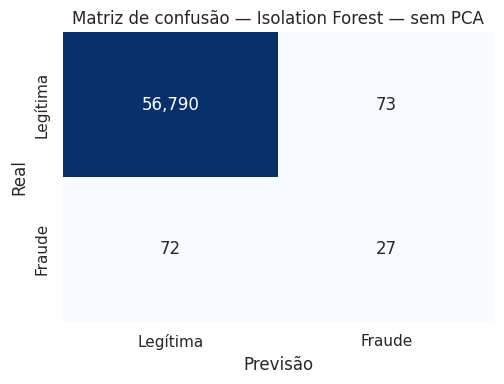

Falsos positivos: 73 transações legítimas geraram alerta.
Falsos negativos: 72 fraudes não foram detectadas.
              precision    recall  f1-score   support

    Legítima     0.9987    0.9987    0.9987     56863
      Fraude     0.2700    0.2727    0.2714        99

    accuracy                         0.9975     56962
   macro avg     0.6344    0.6357    0.6350     56962
weighted avg     0.9975    0.9975    0.9975     56962

Configuração escolhida: {'n_estimators': 100, 'contamination': 'taxa_real', 'max_samples': 1024}


### Isolation Forest — com PCA

,accuracy,precision,recall,f1,pr_auc,roc_auc
0,0.9973,0.2128,0.202,0.2073,0.1322,0.9562


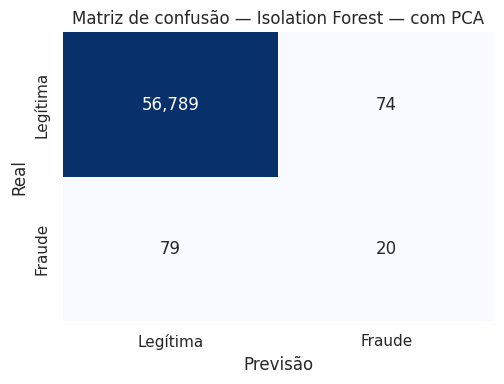

Falsos positivos: 74 transações legítimas geraram alerta.
Falsos negativos: 79 fraudes não foram detectadas.
              precision    recall  f1-score   support

    Legítima     0.9986    0.9987    0.9987     56863
      Fraude     0.2128    0.2020    0.2073        99

    accuracy                         0.9973     56962
   macro avg     0.6057    0.6004    0.6030     56962
weighted avg     0.9972    0.9973    0.9973     56962

Configuração escolhida: {'n_estimators': 100, 'contamination': 'taxa_real', 'max_samples': 1024}


In [ ]:
avaliacoes_if = {}
modelos_if = {}

for usa_pca in [False, True]:
    melhor = (resultados_if_valid[resultados_if_valid["PCA"] == usa_pca]
              .sort_values(["f1", "pr_auc", "recall"], ascending=False).iloc[0])

    etapas = [("escala", StandardScaler())]
    if usa_pca:
        etapas.append(("pca", PCA(n_components=0.95, svd_solver="full")))
    pre = Pipeline(etapas)
    Xt_final = pre.fit_transform(X_treino_final)
    Xts = pre.transform(X_teste)

    modelo = IsolationForest(
        n_estimators=int(melhor["n_estimators"]),
        contamination=float(melhor["contamination"]),
        max_samples=int(melhor["max_samples"]),
        random_state=SEED, n_jobs=-1
    ).fit(Xt_final)
    pred = (modelo.predict(Xts) == -1).astype(int)
    score = -modelo.decision_function(Xts)
    nome = f"Isolation Forest — {'com PCA' if usa_pca else 'sem PCA'}"
    avaliacoes_if[usa_pca] = exibir_avaliacao(nome, y_teste, pred, score)
    modelos_if[usa_pca] = {"preprocessador": pre, "modelo": modelo, "pred": pred, "score": score, "config": melhor}
    print("Configuração escolhida:", {
        "n_estimators": int(melhor["n_estimators"]),
        "contamination": melhor["contamination_label"],
        "max_samples": int(melhor["max_samples"]),
    })

## 3.3 Discussão dos resultados do Isolation Forest

### 3.3.1 Sensibilidade ao parâmetro `contamination`

`contamination` define a proporção esperada de anomalias e influencia diretamente o limiar de decisão. Um valor maior costuma classificar mais transações como suspeitas: pode aumentar o recall, mas também elevar bastante os falsos positivos. A tabela e o gráfico abaixo mostram esse comportamento com e sem PCA.

,PCA,contamination_label,precision,recall,f1,FP,FN
0,False,0.001,0.2924,0.1667,0.2120,39.0000,81.6667
1,False,0.01,0.0991,0.5782,0.1692,515.1667,41.3333
2,False,0.05,0.0277,0.8231,0.0536,2830.8333,17.3333
3,False,taxa_real,0.2587,0.2381,0.2478,67.1667,74.6667
4,True,0.001,0.1464,0.0799,0.1033,44.6667,90.1667
5,True,0.01,0.0758,0.4507,0.1298,538.6667,53.8333
6,True,0.05,0.0267,0.8061,0.0516,2884.6667,19.0000
7,True,taxa_real,0.1515,0.1497,0.1506,82.0000,83.3333


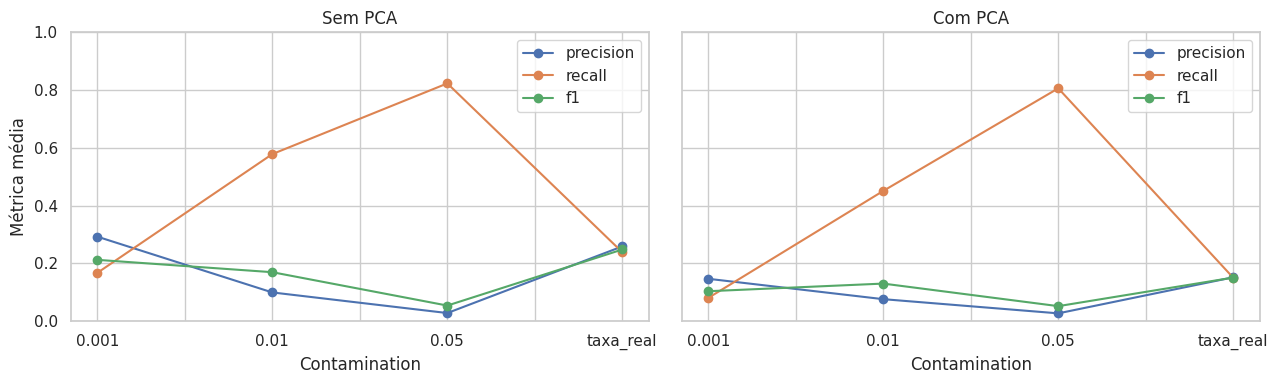

sem PCA: recall=0.273, precision=0.270, FP=73, FN=72.
com PCA: recall=0.202, precision=0.213, FP=74, FN=79.


In [ ]:
impacto_contaminacao = (resultados_if_valid
    .groupby(["PCA", "contamination_label"])[["precision", "recall", "f1", "FP", "FN"]]
    .mean().reset_index())
display(impacto_contaminacao.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, usa_pca in zip(axes, [False, True]):
    dados = impacto_contaminacao[impacto_contaminacao["PCA"] == usa_pca]
    dados.plot(x="contamination_label", y=["precision", "recall", "f1"], marker="o", ax=ax)
    ax.set(title="Com PCA" if usa_pca else "Sem PCA", xlabel="Contamination", ylabel="Métrica média")
    ax.set_ylim(0, 1)
plt.tight_layout()
plt.show()

for usa_pca in [False, True]:
    m = avaliacoes_if[usa_pca]
    cenario = "com PCA" if usa_pca else "sem PCA"
    print(f"{cenario}: recall={m['recall']:.3f}, precision={m['precision']:.3f}, FP={m['FP']:,}, FN={m['FN']:,}.")

### 3.3.2 Capacidade de detectar fraudes sem rótulos

O Isolation Forest encontrou parte das fraudes sem receber `y_treino` durante o ajuste, demonstrando que padrões anômalos carregam alguma informação útil. Porém, seu melhor cenário sem PCA alcançou recall de apenas 0,2727: detectou 27 das 99 fraudes do teste. Isso confirma que anomalia e fraude não são conceitos equivalentes.

### 3.3.3 Sensibilidade observada ao `contamination`

Sem PCA, aumentar `contamination` para 0,05 elevou o recall médio para 0,8231, mas produziu aproximadamente 2.831 falsos positivos. A configuração baseada na taxa real apresentou um equilíbrio melhor, com F1 médio de 0,2478, e foi selecionada no modelo final.

Esse resultado mostra que `contamination` não melhora o detector gratuitamente: valores altos encontram mais fraudes porque classificam muito mais transações como anômalas, aumentando também o trabalho de revisão.

### 3.3.4 Limitações da abordagem

- “Raro” não significa necessariamente “fraudulento”.
- Fraudes que imitam transações comuns podem não ser isoladas.
- O resultado é sensível a `contamination`, `max_samples` e ao pré-processamento.
- Sua explicação é menos direta que a dos coeficientes de uma Regressão Logística.
- Usar rótulos para escolher a melhor configuração torna a seleção experimental parcialmente orientada por supervisão, embora o ajuste do modelo continue sem `y`.

### 3.3.5 Análise de falsos positivos e falsos negativos

No teste sem PCA, o Isolation Forest gerou 73 falsos positivos e 72 falsos negativos. Com PCA, foram 74 falsos positivos e 79 falsos negativos. Portanto, o segundo PCA praticamente não alterou os alertas indevidos, mas fez o detector deixar passar sete fraudes adicionais.

Comparado à Regressão Logística sem PCA, o Isolation Forest produziu 63 falsos positivos e 38 falsos negativos adicionais. Neste conjunto, os rótulos históricos forneceram uma vantagem importante sobre a detecção baseada apenas em raridade.

# Parte 4 — Comparação Crítica

Reunimos os quatro melhores cenários no mesmo quadro. Para fraude, um modelo útil precisa equilibrar detecção e volume de alertas — não apenas acertar a maioria legítima.

,método,PCA,accuracy,precision,recall,f1,pr_auc,roc_auc,FP,FN,VP,VN
0,Regressão Logística,Sem,0.9992,0.8667,0.6566,0.7471,0.7718,0.9669,10,34,65,56853
1,Regressão Logística,Com,0.9991,0.8571,0.6061,0.7101,0.7456,0.9670,10,39,60,56853
2,Isolation Forest,Sem,0.9975,0.2700,0.2727,0.2714,0.2195,0.9541,73,72,27,56790
3,Isolation Forest,Com,0.9973,0.2128,0.2020,0.2073,0.1322,0.9562,74,79,20,56789


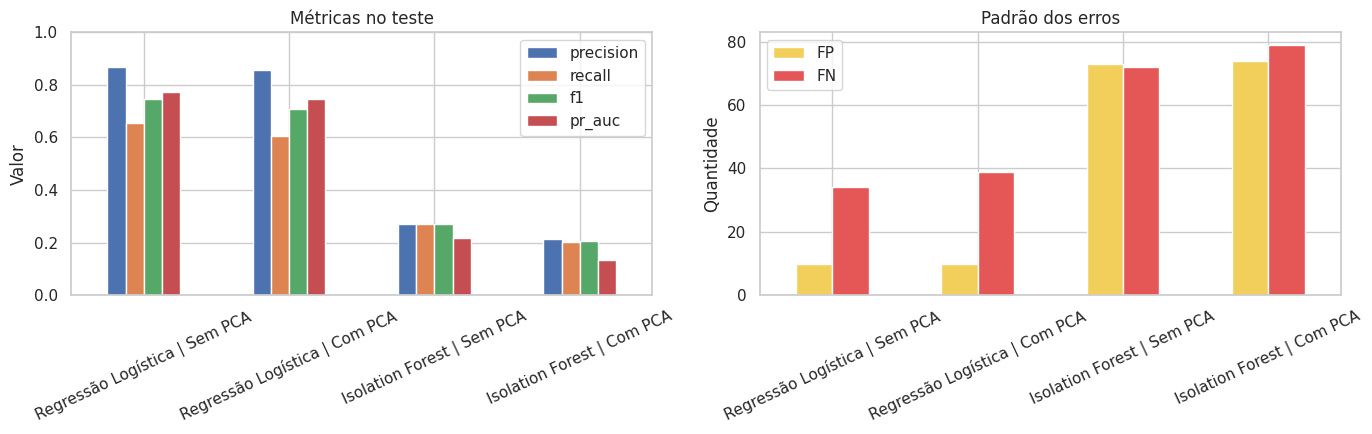

In [ ]:
linhas = []
for metodo, avaliacoes in [("Regressão Logística", avaliacoes_lr), ("Isolation Forest", avaliacoes_if)]:
    for usa_pca, metricas in avaliacoes.items():
        linhas.append({"método": metodo, "PCA": "Com" if usa_pca else "Sem", **metricas})

comparacao = pd.DataFrame(linhas)
cols = ["método", "PCA", "accuracy", "precision", "recall", "f1", "pr_auc", "roc_auc", "FP", "FN", "VP", "VN"]
display(comparacao[cols].sort_values("f1", ascending=False)
        .round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_df = comparacao.copy()
plot_df["cenário"] = plot_df["método"] + " | " + plot_df["PCA"] + " PCA"
plot_df.set_index("cenário")[["precision", "recall", "f1", "pr_auc"]].plot(kind="bar", ax=axes[0])
axes[0].set(title="Métricas no teste", xlabel="", ylabel="Valor", ylim=(0, 1))
axes[0].tick_params(axis="x", rotation=25)
plot_df.set_index("cenário")[["FP", "FN"]].plot(kind="bar", ax=axes[1], color=["#F2CF5B", "#E45756"])
axes[1].set(title="Padrão dos erros", xlabel="", ylabel="Quantidade")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

In [ ]:
melhor_geral = comparacao.sort_values(["f1", "pr_auc", "recall"], ascending=False).iloc[0]
menor_fn = comparacao.sort_values(["FN", "FP"]).iloc[0]
menor_fp = comparacao.sort_values(["FP", "FN"]).iloc[0]

display(Markdown(f'''
### Leitura objetiva dos resultados

- **Melhor F1:** {melhor_geral['método']} ({melhor_geral['PCA']} PCA), com F1 de **{melhor_geral['f1']:.4f}**.
- **Menor quantidade de falsos negativos:** {menor_fn['método']} ({menor_fn['PCA']} PCA), com **{int(menor_fn['FN'])} FN**.
- **Menor quantidade de falsos positivos:** {menor_fp['método']} ({menor_fp['PCA']} PCA), com **{int(menor_fp['FP'])} FP**.

Uma operação que prioriza evitar perdas pode aceitar mais FP para reduzir FN. Já uma operação com revisão manual limitada pode exigir maior precision e menos FP. O efeito do PCA não deve ser presumido: ele é observado comparando as linhas “Com” e “Sem” na tabela.
'''))


### Leitura objetiva dos resultados

- **Melhor F1:** Regressão Logística (Sem PCA), com F1 de **0.7471**.
- **Menor quantidade de falsos negativos:** Regressão Logística (Sem PCA), com **34 FN**.
- **Menor quantidade de falsos positivos:** Regressão Logística (Sem PCA), com **10 FP**.

Uma operação que prioriza evitar perdas pode aceitar mais FP para reduzir FN. Já uma operação com revisão manual limitada pode exigir maior precision e menos FP. O efeito do PCA não deve ser presumido: ele é observado comparando as linhas “Com” e “Sem” na tabela.


## 4.1 Por que o desempenho foi pior com PCA?

O segundo PCA não melhorou nenhum dos modelos. Na Regressão Logística, o F1 caiu de 0,7471 para 0,7101 e os falsos negativos aumentaram de 34 para 39. No Isolation Forest, o F1 caiu de 0,2714 para 0,2073 e os falsos negativos aumentaram de 72 para 79.

Esse comportamento é coerente com a natureza do PCA:

1. **PCA preserva variância, não separação entre classes.** Os componentes são escolhidos sem utilizar `Class`. Uma direção de baixa variância pode ter pouca importância para o conjunto inteiro, mas ainda ser útil para identificar a classe rara.
2. **A fraude representa apenas 0,17% da base.** A variância global é dominada pelas transações legítimas. Preservar 95% dessa variância não garante preservar 95% do sinal relacionado às fraudes.
3. **`V1` a `V28` já vieram de um PCA anterior.** A nova transformação rotacionou novamente os atributos e reduziu apenas de 30 para 27 dimensões. O ganho de simplicidade foi pequeno, enquanto três dimensões foram descartadas.
4. **O Isolation Forest depende de cortes nos eixos.** Uma nova rotação pode distribuir um padrão antes concentrado em um atributo entre vários componentes, tornando algumas anomalias mais difíceis de isolar.

A ROC-AUC permaneceu praticamente igual nos dois cenários, mas recall, F1, PR-AUC e matrizes de confusão pioraram com PCA. Isso indica que o ranqueamento geral continuou parecido, porém a identificação prática da classe rara no limiar utilizado foi inferior. Para esta base e estes parâmetros, a versão sem o segundo PCA foi a escolha mais adequada.

| Critério | Regressão Logística | Isolation Forest |
|---|---|---|
| Desempenho esperado | Geralmente melhor quando há bons rótulos históricos | Pode perder precisão ao confundir raridade com fraude |
| Desbalanceamento | `class_weight` permite tratar diretamente | `contamination` controla quantos casos viram anomalia |
| Interpretabilidade | Coeficientes permitem explicar direção e força | Menos transparente; score indica anomalia, não causa |
| Dependência de rótulos | Precisa de fraudes rotuladas | Treina sem rótulos |
| Uso prático | Decisão principal quando há histórico confiável | Triagem, descoberta de padrões novos e apoio ao supervisionado |
| Erros | Limiar e pesos alteram FP/FN | `contamination` altera fortemente FP/FN |

**Matrizes de confusão:** as quatro matrizes anteriores mostram exatamente onde cada cenário erra. A comparação numérica de FP e FN é mais informativa do que a acurácia, pois evidencia o custo operacional e o risco financeiro.

# Parte 5 — Reflexão Final

### Em que cenário usar cada abordagem?

- **Regressão Logística:** quando existem rótulos confiáveis e se deseja uma decisão simples, rápida e relativamente explicável. É adequada como modelo principal ou *baseline* (referência inicial).
- **Isolation Forest:** quando há poucos rótulos, suspeita de padrões inéditos ou necessidade de priorizar transações fora do comportamento comum. Funciona bem como ferramenta de triagem.

### É possível combinar os métodos?

Sim. O score de anomalia do Isolation Forest pode entrar como um atributo adicional da Regressão Logística, ou ambos podem formar um conjunto de regras: alertar quando qualquer modelo sinaliza aumenta recall; alertar apenas quando ambos concordam tende a aumentar precision. A escolha depende do custo de FP e FN.

### Conexão com outros domínios

O mesmo raciocínio aparece em invasões de rede, falhas industriais, diagnósticos raros, lavagem de dinheiro e defeitos de fabricação. Em todos esses casos, eventos importantes são escassos, os padrões mudam e a acurácia isolada pode esconder um sistema inútil.

### Limitações e próximos passos

- Os dados são históricos e anonimizados; custos reais de cada erro não estão disponíveis.
- O limiar padrão nem sempre é o melhor. Em produção, deve-se escolher o limiar usando custo financeiro e capacidade de revisão.
- Validação temporal seria preferível se houvesse datas completas, pois simula melhor a chegada de novas transações.
- Monitoramento de mudança de comportamento (*data drift*) e retreinamento são necessários em produção.

# Sumário final

1. **Análise exploratória:** medimos o forte desbalanceamento, verificamos tipos, escala e valores ausentes, e explicamos por que acurácia não basta.
2. **Regressão Logística:** testamos L1, L2 e ElasticNet, quatro valores de `C`, pesos padrão/balanceado e versões com/sem PCA.
3. **Isolation Forest:** variamos árvores, `contamination` — inclusive a taxa real —, `max_samples` e versões com/sem PCA.
4. **Avaliação:** usamos validação para escolher configurações e teste separado para medir precision, recall, F1, PR-AUC, ROC-AUC, FP e FN.
5. **Comparação:** discutimos desempenho, robustez ao desbalanceamento, interpretabilidade, dependência de rótulos e uso real.
6. **Conclusão:** Regressão Logística é a escolha natural com bons rótulos; Isolation Forest complementa a análise ao procurar novidades. A decisão final deve considerar principalmente o custo relativo de falsos positivos e falsos negativos.

7. **Efeito do PCA:** a nova redução de 30 para 27 atributos piorou F1, PR-AUC e falsos negativos nos dois métodos; portanto, o melhor cenário foi a Regressão Logística sem o segundo PCA.